In [4]:
from pathlib import Path
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.feature_extraction.text import TfidfVectorizer
from sentence_transformers import SentenceTransformer

In [5]:
# Set the project root
project_root = Path.cwd().parent
project_root

# Set the path to the dataset
data_path = project_root/"data"/"emails.csv"

#load the dataset
emails = pd.read_csv(data_path)
emails.shape
emails.head()

# Check the distribution of the target variable
print("Class Distribution:")
print(round(emails['spam'].value_counts(normalize=True), 2))

Class Distribution:
spam
0    0.76
1    0.24
Name: proportion, dtype: float64


In [6]:
#Set the features and target variable
X = emails['text']
y = emails['spam']

In [7]:
#Split the dataset into training and testing sets
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
                                                    X, 
                                                    y, 
                                                    test_size=0.3, 
                                                    random_state=21,
                                                    stratify=y
                                                    )

In [ ]:
#Load the pretrained sentence transformer model
encoder = SentenceTransformer("all-MiniLM-L6-v2")

In [10]:
# Encode the training and testing data using the pretrained model. We will use spam email text as input to the model and get the embeddings as output. The embeddings will be used as features for the classification model.
X_train = encoder.encode(X_train_raw.tolist(), show_progress_bar=True)
X_test = encoder.encode(X_test_raw.tolist(), show_progress_bar=True)

Batches:   0%|          | 0/126 [00:00<?, ?it/s]

Batches:   0%|          | 0/54 [00:00<?, ?it/s]

In [11]:
#Train the logistic regression model using the training data which is the semantic embeddings of the email text and the target variable which is the spam label
clf_model = LogisticRegression(max_iter=1000, random_state=21)

#fit the model to the training data
clf_model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,21
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [ ]:
#Assess the model's performance on the test set using the score method of the trained model, which returns the mean accuracy on the given test data and labels.
accuracy = clf_model.score(X_test, y_test)
print("Model Accuracy:", round(accuracy,2))

Model Accuracy: 0.98


Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99      1308
           1       0.97      0.94      0.95       411

    accuracy                           0.98      1719
   macro avg       0.97      0.97      0.97      1719
weighted avg       0.98      0.98      0.98      1719

Confusion Matrix:


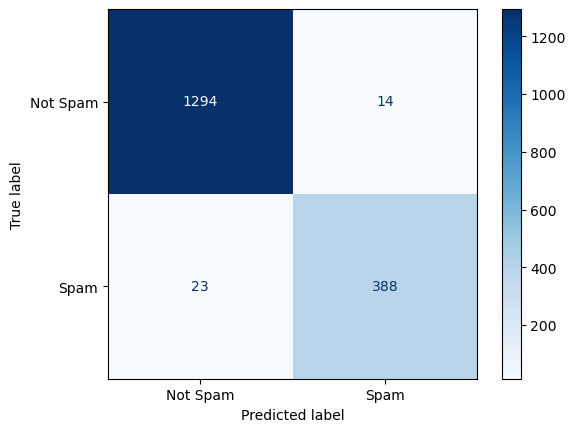

In [14]:
# Let's also generate a classification report and confusion matrix to get a better understanding of the model's performance.
# Generate predictions on the test set
y_pred = clf_model.predict(X_test)

# Generate classification report
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Generate confusion matrix
print("Confusion Matrix:")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['Not Spam', 'Spam'], cmap='Blues')

In [16]:
# Test the model on some example emails
example_emails = ["Your bank account has been hacked. Click on this link to change your password",
                  "Your paymnt for electric bill did not go through. Need urgent action. Click on this link to access your account now or give us a call at this number below",
                  "Click here to get in touch with money doubling consultant now"]

example_embeddings = encoder.encode(example_emails, show_progress_bar=True)
example_predictions = clf_model.predict(example_embeddings)

results = pd.DataFrame({'Email': example_emails, 'Prediction': example_predictions})
results['Prediction'] = results['Prediction'].map({0: 'Not Spam', 1: 'Spam'})
display(results)

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

,Email,Prediction
0,Your bank account has been hacked. Click on th...,Spam
1,Your paymnt for electric bill did not go throu...,Not Spam
2,Click here to get in touch with money doubling...,Spam


In [17]:
# Now, let's use the TFIDF vectorizer approach to see if we can improve the model's performance. We will use the TFIDF vectorizer to convert the email text into numerical features and then train a logistic regression model on these features.
# Initialize the TFIDF vectorizer
tfidf_vectorizer = TfidfVectorizer(stop_words='english', 
                                   max_features=5000, 
                                   ngram_range=(1,2), 
                                   min_df=5, max_df=0.8, 
                                   strip_accents='unicode'
                                    )

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train_raw)
X_test_tfidf = tfidf_vectorizer.transform(X_test_raw)

# Train the logistic regression model using the TFIDF features
clf_model_tfidf = LogisticRegression(max_iter=1000, random_state=21)

# Fit the model to the training data
clf_model_tfidf.fit(X_train_tfidf, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,21
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [ ]:
# Evaluate the TFIDF model's performance on the test set
accuracy_tfidf = clf_model_tfidf.score(X_test_tfidf, y_test)
print("TFIDF Model Accuracy:", round(accuracy_tfidf,2))

TFIDF Model Accuracy: 0.98


TFIDF Model Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1308
           1       1.00      0.93      0.96       411

    accuracy                           0.98      1719
   macro avg       0.99      0.96      0.97      1719
weighted avg       0.98      0.98      0.98      1719

TFIDF Model Confusion Matrix:


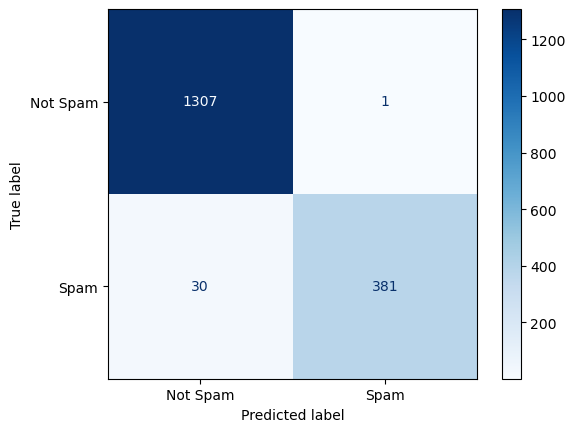

In [19]:
# Let'set's evaluate the TFIDF model's performance using classification report and confusion matrix display as well to get a better understanding of the model's performance.
# Generate predictions on the test set
y_pred_tfidf = clf_model_tfidf.predict(X_test_tfidf)

# Print the classification report
print("TFIDF Model Classification Report:")
print(classification_report(y_test, y_pred_tfidf))

# Print the confusion matrix
print("TFIDF Model Confusion Matrix:")
print(ConfusionMatrixDisplay.from_predictions(y_test, y_pred_tfidf, display_labels=['Not Spam', 'Spam'], cmap='Blues'))

In [21]:
# let's create a comparison of the two models' performance on the test set using a DataFrame to display the accuracy, precision, recall, and F1-score for both models.
# Create a DataFrame to compare the two models' performance
comparison_df = pd.DataFrame({
    'Model': ['Semantic Embeddings', 'TFIDF'],
    'Accuracy': [round(accuracy, 2), round(accuracy_tfidf, 2)],
    'Precision': [round(classification_report(y_test, y_pred, output_dict=True)['1']['precision'], 2), round(classification_report(y_test, y_pred_tfidf, output_dict=True)['1']['precision'], 2)],
    'Recall': [round(classification_report(y_test, y_pred, output_dict=True)['1']['recall'], 2), round(classification_report(y_test, y_pred_tfidf, output_dict=True)['1']['recall'], 2)],
    'F1-Score': [round(classification_report(y_test, y_pred, output_dict=True)['1']['f1-score'], 2), round(classification_report(y_test, y_pred_tfidf, output_dict=True)['1']['f1-score'], 2)]
})

comparison_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Semantic Embeddings,0.98,0.97,0.94,0.95
1,TFIDF,0.98,1.00,0.93,0.96


In [27]:
# let's identify the emails that were misclassified by both models. We will create a DataFrame that contains the email text, the true label, the predicted label from the semantic embeddings model, and the predicted label from the TFIDF model. This will help us understand which emails were difficult for both models to classify correctly.
# Create a DataFrame to identify misclassified emails by both models
misclassified_df = pd.DataFrame({
    'Email': X_test_raw,
    'True Label': y_test,
    'Semantic Embeddings Prediction': y_pred,
    'TFIDF Prediction': y_pred_tfidf
})

# Filter the DataFrame to only include misclassified emails
misclassified_df = misclassified_df[(misclassified_df['True Label'] != misclassified_df['Semantic Embeddings Prediction']) & (misclassified_df['True Label'] != misclassified_df['TFIDF Prediction'])]

# Display the misclassified emails
display(misclassified_df)

,Email,True Label,Semantic Embeddings Prediction,TFIDF Prediction
1222,Subject: luv our rolexes for the same fea - tu...,1,0,0
725,Subject: unbiased info for investor intelligen...,1,0,0
1180,Subject: call for papers : the international j...,1,0,0
122,Subject: help television in 1919 by seat to m...,1,0,0
1267,Subject: underpriced issue with high return on...,1,0,0
401,Subject: nymex invitation - learn power tradin...,1,0,0
568,Subject: . jif .,1,0,0


In [28]:
# now let's identify the emails that were misclassified by the semantic embeddings model but correctly classified by the TFIDF model. We will create a DataFrame that contains the email text, the true label, the predicted label from the semantic embeddings model, and the predicted label from the TFIDF model. This will help us understand which emails were difficult for the semantic embeddings model to classify correctly but were correctly classified by the TFIDF model.
# Create a DataFrame to identify emails misclassified by the semantic embeddings model but correctly classified by the TFIDF model
misclassified_semantic_df = pd.DataFrame({
    'Email': X_test_raw,
    'True Label': y_test,
    'Semantic Embeddings Prediction': y_pred,
    'TFIDF Prediction': y_pred_tfidf
})

# Filter the DataFrame to only include emails misclassified by the semantic embeddings model but correctly classified by the TFIDF model
misclassified_semantic_df = misclassified_semantic_df[(misclassified_semantic_df['True Label'] != misclassified_semantic_df['Semantic Embeddings Prediction']) & (misclassified_semantic_df['True Label'] == misclassified_semantic_df['TFIDF Prediction'])]

# Display the emails misclassified by the semantic embeddings model but correctly classified by the TFIDF model
display(misclassified_semantic_df)

,Email,True Label,Semantic Embeddings Prediction,TFIDF Prediction
1299,"Subject: tetm : 22 , interest : 3 . 55 % ha h...",1,0,1
45,Subject: 1000 full color brochures 335 the ts...,1,0,1
93,Subject: fwd : next tuesday at 9 am for imme...,1,0,1
3524,Subject: holiday gift thank you so much for y...,0,1,0
4194,Subject: re : digitals many thanks . gillian .,0,1,0
49,"Subject: breaking biotech news hey , i though...",1,0,1
1475,Subject: re : site license for power world i ...,0,1,0
559,Subject: urgent contact from the desk of : dr...,1,0,1
2709,"Subject: fw : citi , wells , enron , sl and i ...",0,1,0
2398,Subject: btrieve free ride ends network world...,0,1,0


In [29]:
# let's identify the disagreements between the two models' predictions. We will create a DataFrame that contains the email text, the true label, the predicted label from the semantic embeddings model, and the predicted label from the TFIDF model. This will help us understand which emails were classified differently by the two models.
# Create a DataFrame to identify disagreements between the two models' predictions
disagreements_df = pd.DataFrame({
    'Email': X_test_raw,
    'True Label': y_test,
    'Semantic Embeddings Prediction': y_pred,
    'TFIDF Prediction': y_pred_tfidf
})

# Filter the DataFrame to only include emails where the two models disagreed
disagreements_df = disagreements_df[disagreements_df['Semantic Embeddings Prediction'] != disagreements_df['TFIDF Prediction']]

# Display the disagreements between the two models' predictions
display(disagreements_df)

,Email,True Label,Semantic Embeddings Prediction,TFIDF Prediction
1299,"Subject: tetm : 22 , interest : 3 . 55 % ha h...",1,0,1
835,Subject: 75 % reduction in road accidents aug...,1,1,0
45,Subject: 1000 full color brochures 335 the ts...,1,0,1
93,Subject: fwd : next tuesday at 9 am for imme...,1,0,1
3524,Subject: holiday gift thank you so much for y...,0,1,0
4194,Subject: re : digitals many thanks . gillian .,0,1,0
264,Subject: spice up your cellphone with a wallpa...,1,1,0
49,"Subject: breaking biotech news hey , i though...",1,0,1
1475,Subject: re : site license for power world i ...,0,1,0
907,Subject: send real paper greeting cards on - l...,1,1,0
